# 3. Exploratory Data Analysis

This notebook explores the relationship between the borrower characteristics and the target variable `BAD` (1 = the client defaulted on the loan).

The analysis focuses on the variables that show the strongest signals of default risk.

In [1]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv("../data/HMEQ_clean.csv")

In [3]:
df.shape

(5960, 22)

In [4]:
df.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,...,DEBTINC,DEBTINC_missing,DEROG_missing,DELINQ_missing,MORTDUE_missing,YOJ_missing,NINQ_missing,CLAGE_missing,CLNO_missing,VALUE_missing
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,...,NaN,1,0,0,0,0,0,0,0,0
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,...,NaN,1,0,0,0,0,0,0,0,0
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,...,NaN,1,0,0,0,0,0,0,0,0
3,1,1500,NaN,NaN,Unknown,Unknown,NaN,NaN,NaN,NaN,...,NaN,1,1,1,1,1,1,1,1,1
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,...,NaN,1,0,0,0,0,0,0,0,0


Heatmap

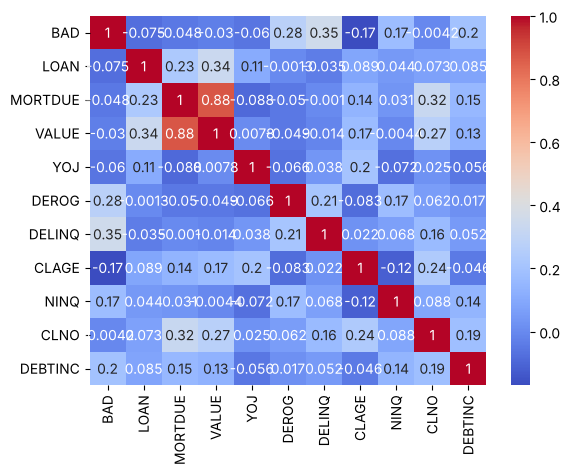

In [5]:
# Draw a heatmap to visualize the correlation between numeric columns
numeric_cols = [
    'BAD',
    'LOAN', 'MORTDUE', 'VALUE', 'YOJ',
    'DEROG', 'DELINQ', 'CLAGE', 'NINQ',
    'CLNO', 'DEBTINC'
]

corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

DELINQ (Number of delinquent credit lines/accounts)

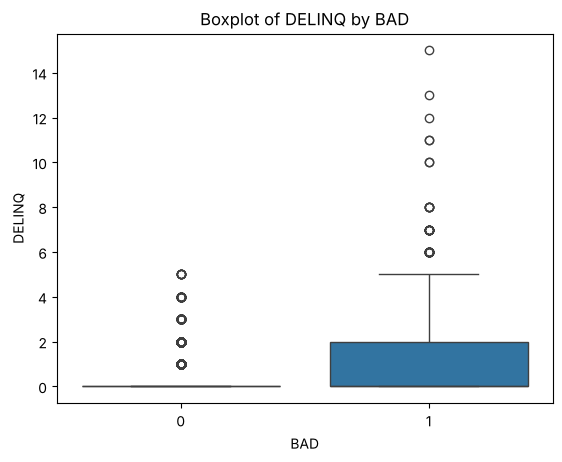

In [6]:
# Show the correlation between 'DELINQ' and 'BAD'
sns.boxplot(
    data=df,
    x='BAD',
    y='DELINQ'
)

plt.title('Boxplot of DELINQ by BAD')
plt.show()

In [7]:
# Count the number of occurrences and calculate the mean of 'BAD' for each 'DELINQ' value
df.groupby('DELINQ')['BAD'].agg(['count', 'mean'])

,count,mean
DELINQ,,
0.0,4179,0.139507
1.0,654,0.339450
2.0,250,0.448000
3.0,129,0.550388
4.0,78,0.589744
5.0,38,0.815789
6.0,27,1.000000
7.0,13,1.000000
8.0,5,1.000000


DEBINT (Debt-to-income ratio.)

In [8]:
df['DEBTINC_bin'] = pd.cut(
    df['DEBTINC'],
    bins=[0, 20, 30, 40, 50, np.inf],
    labels=['<20%', '20-30%', '30-40%', '40-50%', '>50%']
)

df.groupby('DEBTINC_bin', observed=True)['BAD'].agg(['count', 'mean'])

,count,mean
DEBTINC_bin,,
<20%,198,0.106061
20-30%,1150,0.044348
30-40%,2451,0.065687
40-50%,849,0.147232
>50%,45,1.000000


In [9]:
debtinc_default_rate = (
    df.groupby('DEBTINC_bin', observed=True)['BAD']
      .agg(['count', 'mean'])
      .reset_index()
)

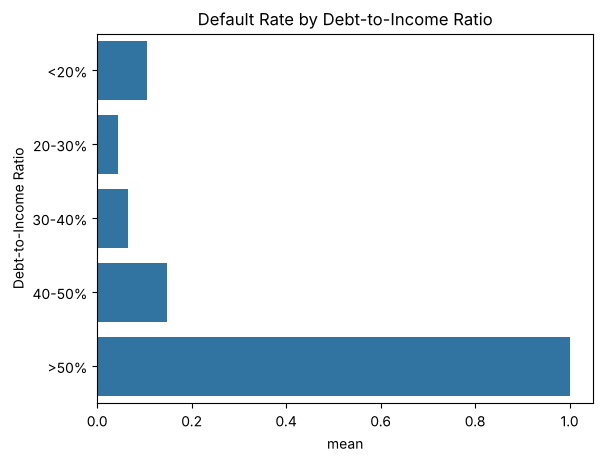

In [10]:
sns.barplot(
    data=debtinc_default_rate,
    x='mean',
    y='DEBTINC_bin'
)

plt.title('Default Rate by Debt-to-Income Ratio')
plt.ylabel('Debt-to-Income Ratio')
plt.show()

DELINQ (Number of delinquent credit lines/accounts. )

In [11]:
df.groupby('DELINQ')['BAD'].agg(['count', 'mean'])

,count,mean
DELINQ,,
0.0,4179,0.139507
1.0,654,0.339450
2.0,250,0.448000
3.0,129,0.550388
4.0,78,0.589744
5.0,38,0.815789
6.0,27,1.000000
7.0,13,1.000000
8.0,5,1.000000


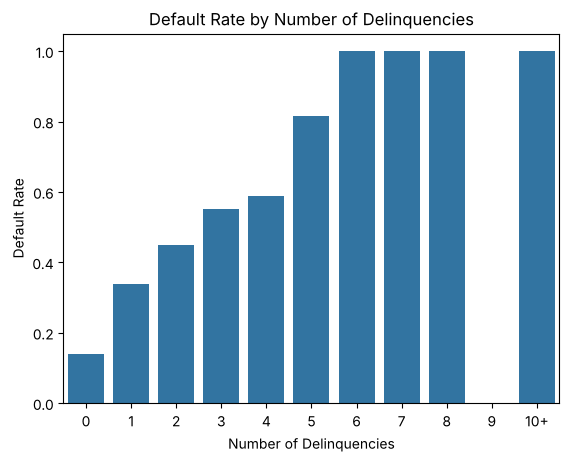

In [12]:
# Create bins for the 'DELINQ' column to group the number of delinquencies
df['DELINQ_bins'] = pd.cut(
    df['DELINQ'],
    bins=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5, np.inf],
    labels=['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10+']
)

delinq_rate = df.groupby('DELINQ_bins', observed=True)['BAD'].mean().reset_index()

sns.barplot(data=delinq_rate, x='DELINQ_bins', y='BAD')

plt.title('Default Rate by Number of Delinquencies')
plt.xlabel('Number of Delinquencies')
plt.ylabel('Default Rate')
plt.show()

DEROG (Number of derogatory credit records.)

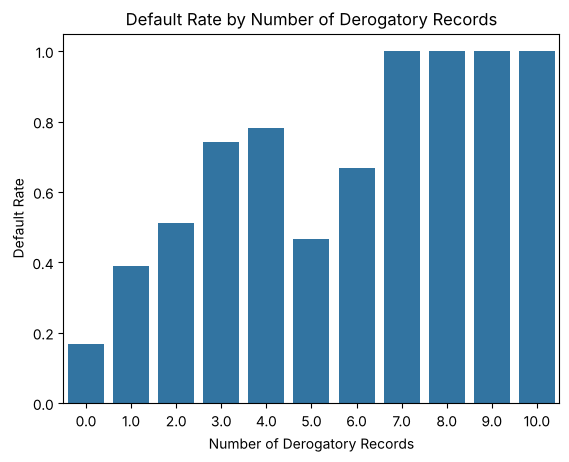

In [13]:
derog_rate = df.groupby('DEROG')['BAD'].agg(['mean', 'count']).reset_index()

sns.barplot(
    data=derog_rate,
    x='DEROG',
    y='mean'
)

plt.xlabel('Number of Derogatory Records')
plt.ylabel('Default Rate')
plt.title('Default Rate by Number of Derogatory Records')
plt.show()

Missing values and default

In [14]:
# Compare the default rate when each variable is missing vs. when it is reported
missing_cols = [col for col in df.columns if col.endswith('_missing')]

missing_default = pd.DataFrame({
    'missing_count': [df[col].sum() for col in missing_cols],
    'default_rate_if_missing': [df.loc[df[col] == 1, 'BAD'].mean() for col in missing_cols],
    'default_rate_if_reported': [df.loc[df[col] == 0, 'BAD'].mean() for col in missing_cols]
}, index=missing_cols)

missing_default.sort_values('default_rate_if_missing', ascending=False).round(3)

,missing_count,default_rate_if_missing,default_rate_if_reported
VALUE_missing,112,0.938,0.185
DEBTINC_missing,1267,0.620,0.086
CLAGE_missing,308,0.253,0.197
CLNO_missing,222,0.239,0.198
MORTDUE_missing,518,0.205,0.199
NINQ_missing,510,0.147,0.204
YOJ_missing,515,0.126,0.206
DELINQ_missing,580,0.124,0.208
DEROG_missing,708,0.123,0.210


The missing values are not random. When `DEBTINC` is missing, the default rate is around **62%**, compared with less than **9%** when it is reported. `VALUE` shows the same pattern, although with fewer observations.

A possible explanation is that applications with incomplete financial information correspond to riskier borrowers. This confirms that creating the `_missing` indicators during the cleaning stage was a good decision, as they will probably be among the most important variables in the model.

## EDA Conclusions

The exploratory analysis identified several relevant patterns associated with loan default.

- `DELINQ` and `DEROG` show a strong positive relationship with observed default rates. Default rates increase substantially as the number of negative credit records increases, although high values should be interpreted cautiously due to smaller sample sizes.
- `DEBTINC` shows a non-linear relationship with default risk, with higher default rates at elevated debt-to-income levels.
- `CLAGE` shows a moderate negative association with default, while `YOJ` has a weaker relationship.
- `MORTDUE` and `VALUE` are highly correlated, which may lead to multicollinearity in linear models.
- Financial variables such as `LOAN`, `MORTDUE`, and `VALUE` are right-skewed and contain extreme observations that should not automatically be removed.
- Missing values are informative: when `DEBTINC` is missing, the default rate rises to around 62%, compared with less than 9% when it is reported.
- Overall, credit history and debt-related variables appear to provide the strongest individual signals of default risk.

These findings support the use of both interpretable linear models and non-linear tree-based models in the modeling stage.